# One month of weather forecasts + Connecticut load: a hefty test run

**Dr. Dave · University of Connecticut** · test notebook, October 2026

[hefty](https://github.com/williamhobbs/hefty) (Will Hobbs, Southern Company) downloads archived weather-model forecasts for any
location. This notebook asks one question: **if we train a load model on the forecast we would really have had, instead of the
weather that actually happened, what does the data look like and how well does a simple model do?**

What it does, top to bottom:
1. **One forecast** - download a single HRRR forecast for Bradley Airport and look at every column.
2. **A month of forecasts** - repeat that for every morning in September 2025 (about 20-25 minutes; progress prints as it goes).
3. **Connecticut load** - read the Lab 5 training file (ISO New England load + Bradley observations) and line it up with the forecasts.
4. **Is the forecast worth it?** The same decision tree three ways - without weather, with Will's forecast, and with the weather
   that actually happened (a cheat, as an upper bound) - all scored on the same held-out week.

Runtime -> Run all. No keys or accounts needed: the forecasts come from NOAA's public archive on AWS.

## Setup
`hefty` needs Python 3.12 or newer (Colab has it). If Colab says the session must restart after the install, click **Restart**
and then **Run all** again - the install is skipped the second time.

In [1]:
# install hefty only if it isn't already here
try:
    import hefty
    print('hefty already installed')
except ImportError:
    !pip install -q hefty

hefty already installed


In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hefty.solar import get_solar_forecast
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings('ignore')        # Herbie/cfgrib are chatty
pd.set_option('display.width', 160)
print('pandas', pd.__version__)

pandas 3.0.6


## Settings
Everything you might change lives in this one dictionary.

In [3]:
SETTINGS = {
    'site': 'Bradley Airport (BDL)',
    'latitude': 41.9389,
    'longitude': -72.6832,
    'model': 'hrrr',                    # 'hrrr' (3 km, NOAA) or 'gfs' (25 km, NOAA)
    'month': '2025-07',                 # try '2025-07' for a hot month
    'init_hour_utc': 12,                # 12:00 UTC = 8 a.m. in Connecticut; one forecast per morning
    'lead_time_to_start': 1,            # first forecast hour = 1 hour after the model starts
    'run_length': 24,                   # forecast the next 24 hours
    'test_days': 7,                     # the last 7 days are held out for testing
    'load_url': 'https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2025.csv',
    'seed': 5509,
}
# derived from the month: first forecast time and number of mornings
first_init = pd.Timestamp(SETTINGS['month'] + '-01') + pd.Timedelta(hours=SETTINGS['init_hour_utc'])
n_days = pd.Timestamp(SETTINGS['month'] + '-01').days_in_month
print('first forecast issued', first_init, 'UTC |', n_days, 'mornings')
SETTINGS

first forecast issued 2025-07-01 12:00:00 UTC | 31 mornings


{'site': 'Bradley Airport (BDL)',
 'latitude': 41.9389,
 'longitude': -72.6832,
 'model': 'hrrr',
 'month': '2025-07',
 'init_hour_utc': 12,
 'lead_time_to_start': 1,
 'run_length': 24,
 'test_days': 7,
 'load_url': 'https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2025.csv',
 'seed': 5509}

## Step 1: one forecast
One call = one model run: the HRRR forecast issued at 8 a.m. on the first day of the month, for the 24 hours after it.

In [4]:
t0 = time.time()
one = get_solar_forecast(SETTINGS['latitude'], SETTINGS['longitude'], first_init,
                         run_length=SETTINGS['run_length'],
                         lead_time_to_start=SETTINGS['lead_time_to_start'],
                         model=SETTINGS['model'], priority='aws')
print('took', round(time.time() - t0), 'seconds')
print('shape:', one.shape, '-> one row per forecast hour, one column per variable')
one.head()

✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Jul-01 12:00 UTC F01 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Jul-01 12:00 UTC F02 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Jul-01 12:00 UTC F03 ┊ GRIB2 @ aws ┊ IDX @ local


...

Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Jul-01 12:00 UTC F24 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Jul-01 12:00 UTC F25 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.
took 50 seconds
shape: (24, 12) -> one row per forecast hour, one column per variable


,point,temp_air,wind_speed,wind_direction,csi_ghi,csi_dni,lead_time,ghi_clear,dni_clear,ghi,dni,dhi
valid_time,,,,,,,,,,,,
2025-07-01 13:30:00+00:00,0,27.058943,5.153012,192.047180,0.437019,0.187504,1.5,743.513548,957.434955,324.331873,179.360307,200.374933
2025-07-01 14:30:00+00:00,0,29.396271,5.605430,205.477295,0.721245,0.350699,2.5,896.210899,992.927284,645.015706,348.007985,361.613058
2025-07-01 15:30:00+00:00,0,30.746233,5.822631,220.731659,0.677839,0.369610,3.5,1003.539907,1013.783987,678.701340,374.529930,341.620281
2025-07-01 16:30:00+00:00,0,31.934248,6.110143,229.892715,0.672860,0.478399,4.5,1056.744568,1023.144108,709.394705,489.269049,248.397109
2025-07-01 17:30:00+00:00,0,32.524582,6.020165,227.311142,0.575780,0.297525,5.5,1051.533968,1022.253033,604.053586,304.018373,318.856860


In [5]:
one.dtypes

point               int64
temp_air          float32
wind_speed        float32
wind_direction    float32
csi_ghi           float64
csi_dni           float64
lead_time         float64
ghi_clear         float64
dni_clear         float64
ghi               float64
dni               float64
dhi               float64
dtype: object

What the columns mean (HRRR):

| column | meaning | units |
|---|---|---|
| index `valid_time` | the hour being forecast (UTC, labelled at the middle of the hour) | timestamp |
| `point` | which site (0 = our only site) | - |
| `temp_air` | air temperature | °C |
| `wind_speed`, `wind_direction` | wind at 10 m | m/s, degrees |
| `ghi` | global horizontal irradiance: all sunlight reaching flat ground | W/m² |
| `dni`, `dhi` | the direct beam and the diffuse (sky) parts of that sunlight | W/m² |
| `ghi_clear`, `dni_clear` | the same, if the sky were perfectly clear | W/m² |
| `csi_ghi`, `csi_dni` | clear-sky index = forecast ÷ clear sky (1 = sunny, near 0 = overcast) | 0-1 |
| `lead_time` | hours between when the forecast was issued and the hour it is for | hours |

## Step 2: a month of forecasts
The same call for every morning in the month. Each run covers the 24 hours after it, so the runs tile the month with no gaps
or overlaps. The finished table is saved to `hefty_forecasts_<month>.csv`, so a re-run reads the file instead of downloading again.

In [6]:
import os

FCST_FILE = 'hefty_forecasts_' + SETTINGS['month'] + '.csv'
if os.path.exists(FCST_FILE):
    fcst = pd.read_csv(FCST_FILE, index_col='valid_time', parse_dates=True)
    print('read', FCST_FILE, 'from disk')
else:
    runs = []
    t0 = time.time()
    for day in range(n_days):
        init = first_init + pd.Timedelta(days=day)
        run = get_solar_forecast(SETTINGS['latitude'], SETTINGS['longitude'], init,
                                 run_length=SETTINGS['run_length'],
                                 lead_time_to_start=SETTINGS['lead_time_to_start'],
                                 model=SETTINGS['model'], priority='aws')
        run['init_time'] = init
        runs.append(run)
        print(f'run {day + 1:2d}/{n_days}  issued {init:%b %d %H:%M} UTC  rows {len(run)}  '
              f'elapsed {round((time.time() - t0) / 60, 1)} min', flush=True)
    fcst = pd.concat(runs)
    fcst.to_csv(FCST_FILE)

print('forecast table shape:', fcst.shape)
print('first hour:', fcst.index.min(), '| last hour:', fcst.index.max())
fcst.head()

read hefty_forecasts_2025-07.csv from disk
forecast table shape: (744, 13)
first hour: 2025-07-01 13:30:00+00:00 | last hour: 2025-08-01 12:30:00+00:00


,point,temp_air,wind_speed,wind_direction,csi_ghi,csi_dni,lead_time,ghi_clear,dni_clear,ghi,dni,dhi,init_time
valid_time,,,,,,,,,,,,,
2025-07-01 13:30:00+00:00,0,27.058943,5.153012,192.04718,0.437019,0.187504,1.5,743.513548,957.434955,324.331873,179.360307,200.374933,2025-07-01 12:00:00
2025-07-01 14:30:00+00:00,0,29.396270,5.605430,205.47730,0.721245,0.350699,2.5,896.210899,992.927284,645.015706,348.007985,361.613058,2025-07-01 12:00:00
2025-07-01 15:30:00+00:00,0,30.746233,5.822631,220.73166,0.677839,0.369610,3.5,1003.539907,1013.783987,678.701340,374.529930,341.620281,2025-07-01 12:00:00
2025-07-01 16:30:00+00:00,0,31.934248,6.110143,229.89272,0.672860,0.478399,4.5,1056.744568,1023.144108,709.394705,489.269049,248.397109,2025-07-01 12:00:00
2025-07-01 17:30:00+00:00,0,32.524582,6.020165,227.31114,0.575780,0.297525,5.5,1051.533968,1022.253033,604.053586,304.018373,318.856860,2025-07-01 12:00:00


In [7]:
# any gaps? (should be 0 missing values and days x 24 rows)
print(fcst.isna().sum())
fcst.describe().round(1)

point             0
temp_air          0
wind_speed        0
wind_direction    0
csi_ghi           0
csi_dni           0
lead_time         0
ghi_clear         0
dni_clear         0
ghi               0
dni               0
dhi               0
init_time         0
dtype: int64


,point,temp_air,wind_speed,wind_direction,csi_ghi,csi_dni,lead_time,ghi_clear,dni_clear,ghi,dni,dhi
count,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0
mean,0.0,24.9,2.9,199.4,0.4,0.3,13.0,378.6,516.7,278.7,243.6,109.7
std,0.0,4.5,1.4,80.0,0.4,0.3,6.9,403.6,450.9,322.9,302.7,131.1
min,0.0,14.1,0.4,1.7,0.0,0.0,1.5,0.0,0.0,0.0,0.0,0.0
25%,0.0,21.8,1.9,160.1,0.0,0.0,7.2,0.0,0.0,0.0,0.0,0.0
50%,0.0,24.5,2.7,179.8,0.4,0.1,13.0,214.4,687.9,93.7,23.3,70.4
75%,0.0,28.0,3.7,246.6,0.8,0.6,18.8,765.7,962.8,554.6,510.8,171.8
max,0.0,37.0,8.8,358.9,0.9,0.9,24.5,1056.7,1023.1,981.6,894.3,643.1


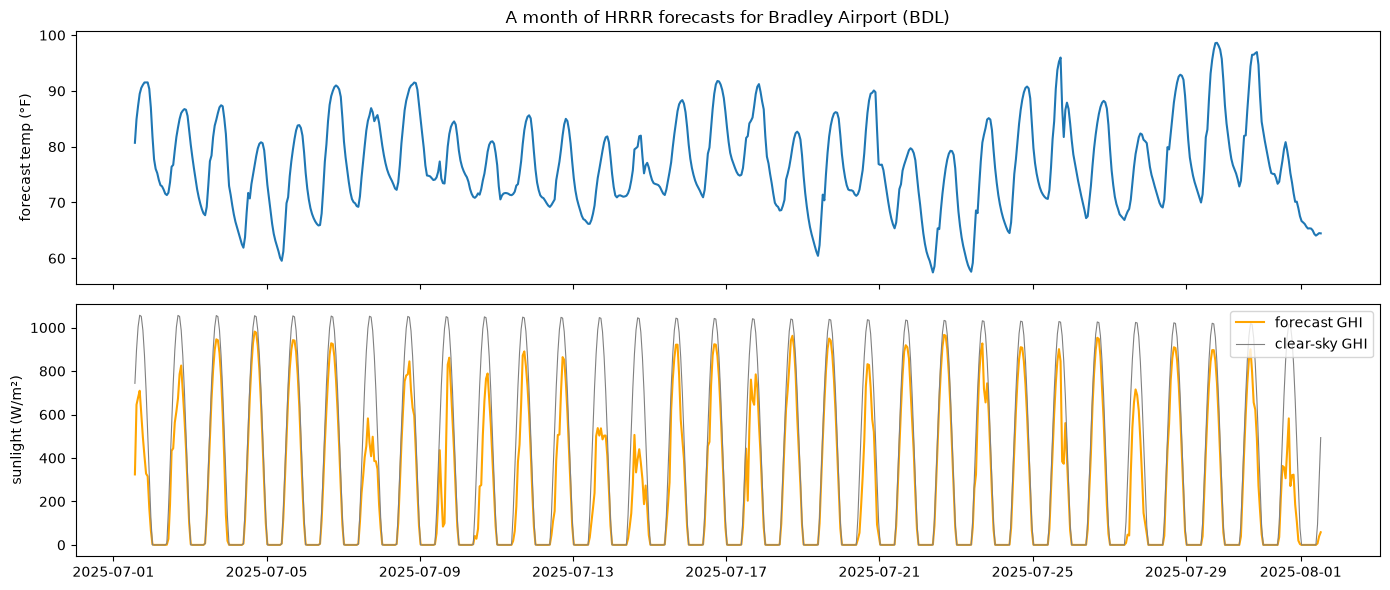

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(fcst.index, fcst['temp_air'] * 9 / 5 + 32)
axes[0].set_ylabel('forecast temp (°F)')
axes[1].plot(fcst.index, fcst['ghi'], color='orange', label='forecast GHI')
axes[1].plot(fcst.index, fcst['ghi_clear'], color='grey', linewidth=0.8, label='clear-sky GHI')
axes[1].set_ylabel('sunlight (W/m²)')
axes[1].legend()
axes[0].set_title('A month of HRRR forecasts for ' + SETTINGS['site'])
plt.tight_layout()
plt.show()

## Step 3: Connecticut load
The Lab 5 training file: one row per hour, ISO New England's Connecticut-zone load plus what was actually observed at Bradley.
`hour_utc` is the start of each hour, so we line the forecast up by rounding its mid-hour label down to the start of the hour.

In [9]:
load = pd.read_csv(SETTINGS['load_url'])
load['hour_utc'] = pd.to_datetime(load['hour_utc'], utc=True)
load = load.set_index('hour_utc')
print('full load file shape:', load.shape)
load[['load_mw', 'temp_f', 'cloud_cover_pct']].head()

full load file shape: (26304, 17)


,load_mw,temp_f,cloud_cover_pct
hour_utc,,,
2023-01-01 05:00:00+00:00,2402.708,50.0,100.0
2023-01-01 06:00:00+00:00,2296.444,50.0,100.0
2023-01-01 07:00:00+00:00,2206.413,50.0,100.0
2023-01-01 08:00:00+00:00,2165.396,48.0,75.0
2023-01-01 09:00:00+00:00,2153.655,48.0,44.0


In [10]:
# same hour yesterday: the simplest possible forecast, and the baseline to beat
load['load_yesterday_mw'] = load['load_mw'].shift(24)

fcst['hour_utc'] = fcst.index.floor('h')
data = fcst.reset_index().merge(load[['load_mw', 'load_yesterday_mw', 'temp_f', 'cloud_cover_pct']], left_on='hour_utc', right_index=True, how='inner')
data = data.set_index('hour_utc').sort_index()
data['temp_fcst_f'] = data['temp_air'] * 9 / 5 + 32
print('joined shape:', data.shape, '-> every forecast hour now has the load that actually happened')
data[['temp_fcst_f', 'temp_f', 'ghi', 'csi_ghi', 'load_mw', 'load_yesterday_mw']].head()

joined shape: (744, 19) -> every forecast hour now has the load that actually happened


,temp_fcst_f,temp_f,ghi,csi_ghi,load_mw,load_yesterday_mw
hour_utc,,,,,,
2025-07-01 13:00:00+00:00,80.706097,78.0,324.331873,0.437019,4050.714,3541.630
2025-07-01 14:00:00+00:00,84.913286,80.0,645.015706,0.721245,4206.318,3766.553
2025-07-01 15:00:00+00:00,87.343219,82.0,678.701340,0.677839,4347.420,3976.442
2025-07-01 16:00:00+00:00,89.481646,86.0,709.394705,0.672860,4607.886,4227.359
2025-07-01 17:00:00+00:00,90.544248,89.0,604.053586,0.575780,4940.005,4440.925


forecast temperature error: mean 1.2 °F | mean absolute 2.4 °F


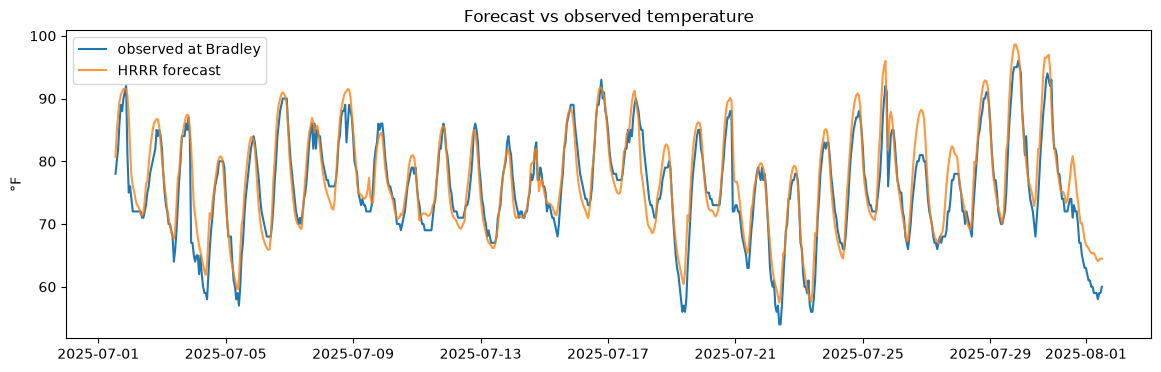

In [11]:
# how good was the forecast? compare forecast temperature with what Bradley actually measured
err = data['temp_fcst_f'] - data['temp_f']
print('forecast temperature error: mean', round(err.mean(), 1), '°F | mean absolute', round(err.abs().mean(), 1), '°F')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(data.index, data['temp_f'], label='observed at Bradley')
ax.plot(data.index, data['temp_fcst_f'], label='HRRR forecast', alpha=0.8)
ax.set_ylabel('°F')
ax.legend()
ax.set_title('Forecast vs observed temperature')
plt.show()

### Why sunlight matters for Connecticut load
ISO New England's load is what the grid supplies *after* rooftop solar. On a sunny afternoon the panels cover part of the
demand, so the measured load dips. Below: midday hours (11 a.m.-3 p.m. local), sunny vs cloudy.

midday rows: (155, 21)


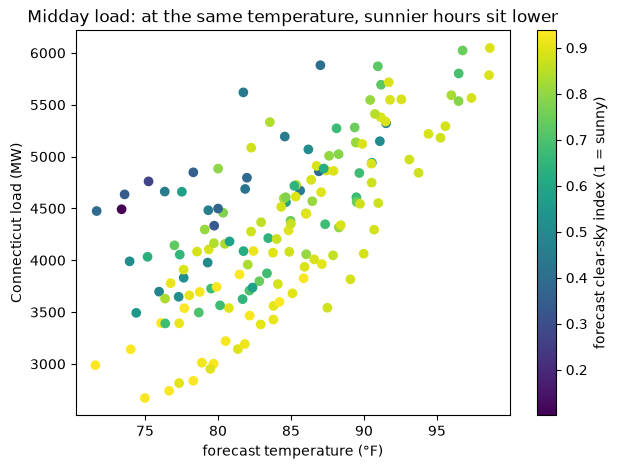

In [12]:
data['hour_local'] = data.index.tz_convert('America/New_York').hour
data['day_of_week'] = data.index.tz_convert('America/New_York').dayofweek
midday = data[(data['hour_local'] >= 11) & (data['hour_local'] <= 15)]
print('midday rows:', midday.shape)

fig, ax = plt.subplots(figsize=(7, 5))
points = ax.scatter(midday['temp_fcst_f'], midday['load_mw'], c=midday['csi_ghi'], cmap='viridis')
plt.colorbar(points, label='forecast clear-sky index (1 = sunny)')
ax.set_xlabel('forecast temperature (°F)')
ax.set_ylabel('Connecticut load (MW)')
ax.set_title('Midday load: at the same temperature, sunnier hours sit lower')
plt.show()

## Step 4: is the forecast worth it?
The same decision tree, trained three ways and scored on the same held-out last week. The only thing that changes is which
columns it is allowed to see:

| model | it sees | why it's here |
|---|---|---|
| **no weather** | hour of day, day of week, load at the same hour yesterday | what you could do with no weather data at all |
| **+ hefty forecast** | the above + the HRRR forecast (temperature, sunlight, clear-sky index, wind) | the honest version: only what was known at 8 a.m. |
| **+ actual weather** | the above + what Bradley really measured (temperature, cloud cover) | a cheat - nobody knows tomorrow's weather - so it shows the most a perfect forecast could add |

Plus the plain baseline, "same hour yesterday". If **+ hefty forecast** beats **no weather**, the forecast has value; how close it
gets to **+ actual weather** shows how much a better forecast could still add. Train on the first 23 days, test on the last 7, in
time order (no shuffling - the future can't leak into training).

In [13]:
TARGET = 'load_mw'
FEATURE_SETS = {
    'no weather': ['hour_local', 'day_of_week', 'load_yesterday_mw'],
    '+ hefty forecast': ['hour_local', 'day_of_week', 'load_yesterday_mw', 'temp_fcst_f', 'ghi', 'csi_ghi', 'wind_speed'],
    '+ actual weather (cheat)': ['hour_local', 'day_of_week', 'load_yesterday_mw', 'temp_f', 'cloud_cover_pct'],
}

data = data.dropna(subset=['load_yesterday_mw'])
cut = data.index.max() - pd.Timedelta(days=SETTINGS['test_days'])
train = data[data.index <= cut]
test = data[data.index > cut]
y_train = train[TARGET]
y_test = test[TARGET]
print('train:', train.shape, '| test:', test.shape)
print('training hours:', train.index.min(), '->', train.index.max())
print('testing hours: ', test.index.min(), '->', test.index.max())

train: (576, 21) | test: (168, 21)
training hours: 2025-07-01 13:00:00+00:00 -> 2025-07-25 12:00:00+00:00
testing hours:  2025-07-25 13:00:00+00:00 -> 2025-08-01 12:00:00+00:00


In [14]:
results = {}
predictions = {}
trees = {}
results['same hour yesterday'] = mean_absolute_error(y_test, test['load_yesterday_mw'])
predictions['same hour yesterday'] = test['load_yesterday_mw'].values

for name in FEATURE_SETS:
    cols = FEATURE_SETS[name]
    X_train = train[cols]
    X_test = test[cols]
    print(name.ljust(26), 'X_train', X_train.shape, ' X_test', X_test.shape)
    tree = DecisionTreeRegressor(max_depth=6, min_samples_leaf=5, random_state=SETTINGS['seed'])
    tree.fit(X_train, y_train)
    predictions[name] = tree.predict(X_test)
    results[name] = mean_absolute_error(y_test, predictions[name])
    trees[name] = tree

scoreboard = pd.DataFrame({'test MAE (MW)': pd.Series(results)})
scoreboard['% of average load'] = 100 * scoreboard['test MAE (MW)'] / y_test.mean()
scoreboard = scoreboard.sort_values('test MAE (MW)').round(1)
print()
print('average load in the test week:', round(y_test.mean()), 'MW')
scoreboard

no weather                 X_train (576, 3)  X_test (168, 3)
+ hefty forecast           X_train (576, 7)  X_test (168, 7)
+ actual weather (cheat)   X_train (576, 5)  X_test (168, 5)

average load in the test week: 4149 MW


,test MAE (MW),% of average load
+ actual weather (cheat),294.9,7.1
+ hefty forecast,432.8,10.4
no weather,508.4,12.3
same hour yesterday,631.3,15.2


In [15]:
gain = results['no weather'] - results['+ hefty forecast']
room = results['+ hefty forecast'] - results['+ actual weather (cheat)']
print('adding the hefty forecast changed the error by', round(-gain, 1), 'MW', '(negative = better)')
print('a perfect forecast could have cut another', round(room, 1), 'MW')

adding the hefty forecast changed the error by -75.6 MW (negative = better)
a perfect forecast could have cut another 137.8 MW


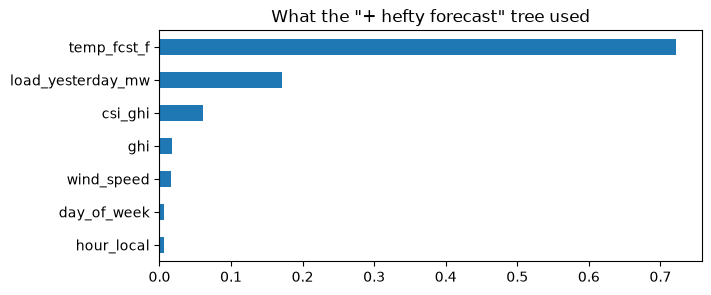

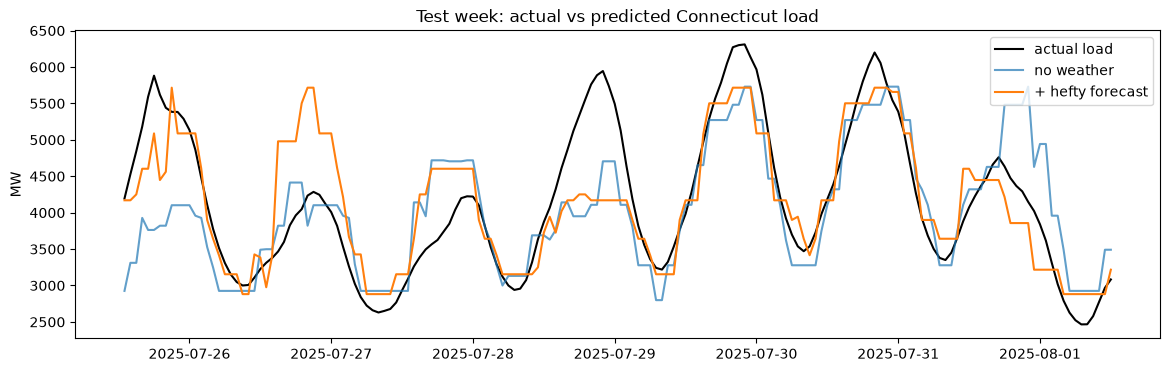

In [16]:
importance = pd.Series(trees['+ hefty forecast'].feature_importances_, index=FEATURE_SETS['+ hefty forecast']).sort_values()
importance.plot(kind='barh', figsize=(7, 3), title='What the "+ hefty forecast" tree used')
plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(test.index, y_test, label='actual load', color='black')
ax.plot(test.index, predictions['no weather'], label='no weather', alpha=0.7)
ax.plot(test.index, predictions['+ hefty forecast'], label='+ hefty forecast')
ax.set_ylabel('MW')
ax.legend()
ax.set_title('Test week: actual vs predicted Connecticut load')
plt.show()

## Step 5: a fairer test - learn from years of history, then feed it the forecast
A month is too little for a tree to learn how weather moves load (Step 4 shows it). So do it the way a real model would be used:
1. **Train** on the years before the test month, using the weather Bradley actually measured.
2. **Test** on the month, feeding the same trained tree either what really happened (the cheat) or Will's 8 a.m. forecast
   (what you would really have).

Two weather inputs: temperature, and **sunlight**. The history file has no sunlight column, so we rebuild it the standard way:
the sunlight a clear sky would give at that hour (pvlib, which comes with hefty) dimmed by the cloud cover Bradley reported.
At test time the forecast version is simply hefty's `ghi`.

In [17]:
import pvlib

hist = load.copy()
local = hist.index.tz_convert('America/New_York')
hist['hour_local'] = local.hour
hist['day_of_week'] = local.dayofweek
hist['month'] = local.month
site = pvlib.location.Location(SETTINGS['latitude'], SETTINGS['longitude'])
clear = site.get_clearsky(hist.index + pd.Timedelta(minutes=30), model='ineichen')     # mid-hour sun
hist['ghi_clear'] = clear['ghi'].values
hist['sun'] = hist['ghi_clear'] * (1 - 0.75 * (hist['cloud_cover_pct'] / 100) ** 3.4)  # Kasten-Czeplak cloud dimming

history = hist[hist.index < data.index.min()].dropna(subset=['load_yesterday_mw', 'sun'])
month_test = hist.loc[data.index].copy()
month_test['temp_fcst_f'] = data['temp_fcst_f']
month_test['sun_fcst'] = data['ghi']
print('history (training):', history.shape, history.index.min(), '->', history.index.max())
print('test month:        ', month_test.shape)
month_test[['load_mw', 'temp_f', 'temp_fcst_f', 'sun', 'sun_fcst']].head()

history (training): (21872, 22) 2023-01-02 05:00:00+00:00 -> 2025-07-01 12:00:00+00:00
test month:         (744, 24)


,load_mw,temp_f,temp_fcst_f,sun,sun_fcst
hour_utc,,,,,
2025-07-01 13:00:00+00:00,4050.714,78.0,80.706097,159.566677,324.331873
2025-07-01 14:00:00+00:00,4206.318,80.0,84.913286,558.296266,645.015706
2025-07-01 15:00:00+00:00,4347.420,82.0,87.343219,628.103636,678.701340
2025-07-01 16:00:00+00:00,4607.886,86.0,89.481646,662.565731,709.394705
2025-07-01 17:00:00+00:00,4940.005,89.0,90.544248,659.193755,604.053586


In [18]:
CLOCK = ['hour_local', 'day_of_week', 'month', 'load_yesterday_mw']
INPUTS = {
    'temperature': CLOCK + ['temp_f'],
    'temperature + sunlight': CLOCK + ['temp_f', 'sun'],
}

fair = {}
fair['same hour yesterday'] = mean_absolute_error(month_test['load_mw'], month_test['load_yesterday_mw'])
tree_clock = DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=SETTINGS['seed'])
tree_clock.fit(history[CLOCK], history['load_mw'])
fair['no weather'] = mean_absolute_error(month_test['load_mw'], tree_clock.predict(month_test[CLOCK]))

for name in INPUTS:
    cols = INPUTS[name]
    tree = DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=SETTINGS['seed'])
    tree.fit(history[cols], history['load_mw'])
    X_actual = month_test[cols]
    X_forecast = month_test[cols].copy()
    X_forecast['temp_f'] = month_test['temp_fcst_f']          # swap in Will's forecast...
    if 'sun' in cols:
        X_forecast['sun'] = month_test['sun_fcst']            # ...for every weather input
    fair[name + ': hefty forecast'] = mean_absolute_error(month_test['load_mw'], tree.predict(X_forecast))
    fair[name + ': actual (cheat)'] = mean_absolute_error(month_test['load_mw'], tree.predict(X_actual))

fair_board = pd.DataFrame({'MAE (MW)': pd.Series(fair)})
fair_board['% of average load'] = 100 * fair_board['MAE (MW)'] / month_test['load_mw'].mean()
fair_board.sort_values('MAE (MW)').round(1)

,MAE (MW),% of average load
temperature: actual (cheat),283.3,7.2
temperature: hefty forecast,287.2,7.3
temperature + sunlight: hefty forecast,290.4,7.4
temperature + sunlight: actual (cheat),290.6,7.4
no weather,409.5,10.4
same hour yesterday,463.7,11.8


In [19]:
possible = fair['no weather'] - fair['temperature + sunlight: actual (cheat)']
captured = fair['no weather'] - fair['temperature + sunlight: hefty forecast']
print('perfect knowledge of temperature + sunlight would cut the error by', round(possible, 1), 'MW')
print('the hefty forecast cut it by', round(captured, 1), 'MW')
print('-> the forecast delivers', round(100 * captured / possible), '% of the possible gain')
print('sunlight on top of temperature (forecast versions):',
      round(fair['temperature: hefty forecast'] - fair['temperature + sunlight: hefty forecast'], 1), 'MW better')

perfect knowledge of temperature + sunlight would cut the error by 118.9 MW
the hefty forecast cut it by 119.1 MW
-> the forecast delivers 100 % of the possible gain
sunlight on top of temperature (forecast versions): -3.2 MW better


## Step 6: does Will's sunlight forecast match real solar?
ISO New England publishes, every 5 minutes, the region's load with and without its **estimate of rooftop (behind-the-meter)
solar**. The difference is the solar it thinks was produced across New England. It's public: the download only needs a normal
browser visit to the page first, which `requests.Session()` does for us.

Note: ISO's rooftop number is itself an estimate built from irradiance data, not a meter reading - but it is the official one.

In [20]:
import io
import requests

session = requests.Session()
session.headers.update({'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/141.0 Safari/537.36'})
landing = session.get('https://www.iso-ne.com/isoexpress/web/reports/operations/-/tree/gen-fuel-mix', timeout=60)
month_start = pd.Timestamp(SETTINGS['month'] + '-01')
month_end = month_start + pd.offsets.MonthEnd(0) + pd.Timedelta(days=1)
url = ('https://www.iso-ne.com/transform/csv/fiveminutesystemload?start=' + month_start.strftime('%Y%m%d')
       + '&end=' + month_end.strftime('%Y%m%d'))
resp = session.get(url, headers={'Referer': landing.url, 'Accept': 'text/csv,*/*'}, timeout=120)
print('ISO-NE status:', resp.status_code)

lines = []
for line in resp.text.splitlines():
    if line.startswith('"D"'):
        lines.append(line)
iso = pd.read_csv(io.StringIO(chr(10).join(lines)), header=None, usecols=[1, 2, 5],
                  names=['time_local', 'ne_load_mw', 'ne_load_with_solar_mw'])
iso['time_local'] = pd.to_datetime(iso['time_local'], format='%m/%d/%Y %H:%M:%S')
iso['hour_utc'] = iso['time_local'].dt.tz_localize('America/New_York', ambiguous='NaT', nonexistent='NaT').dt.tz_convert('UTC').dt.floor('h')
iso = iso.dropna(subset=['hour_utc']).groupby('hour_utc')[['ne_load_mw', 'ne_load_with_solar_mw']].mean()
iso['ne_rooftop_solar_mw'] = iso['ne_load_with_solar_mw'] - iso['ne_load_mw']
print('ISO-NE hourly table:', iso.shape)
iso.head()

ISO-NE status: 200
ISO-NE hourly table: (768, 3)


,ne_load_mw,ne_load_with_solar_mw,ne_rooftop_solar_mw
hour_utc,,,
2025-07-01 04:00:00+00:00,14975.135500,14975.135500,0.0
2025-07-01 05:00:00+00:00,14597.889833,14597.889833,0.0
2025-07-01 06:00:00+00:00,14227.314167,14227.314167,0.0
2025-07-01 07:00:00+00:00,14008.930083,14008.930083,0.0
2025-07-01 08:00:00+00:00,14132.771500,14132.771500,0.0


daylight hours: 447
correlation with ISO rooftop solar:
   hefty forecast GHI              : 0.94
   clear-sky GHI (no clouds at all): 0.882


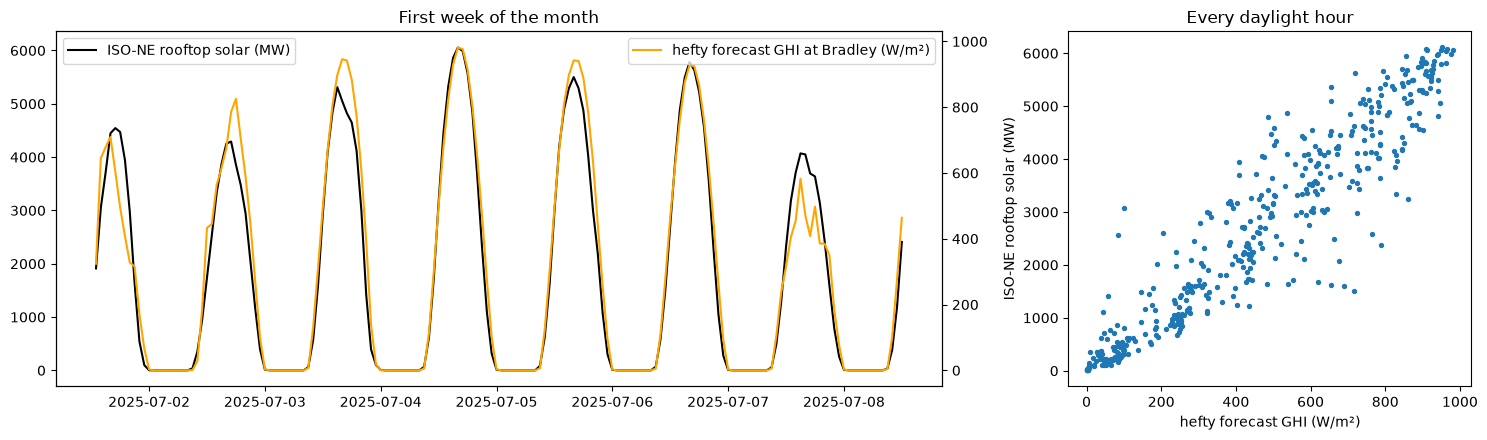

In [21]:
both = data.join(iso, how='inner')
sunny_hours = both[both['ghi_clear'] > 0]
print('daylight hours:', len(sunny_hours))
print('correlation with ISO rooftop solar:')
print('   hefty forecast GHI              :', round(sunny_hours['ne_rooftop_solar_mw'].corr(sunny_hours['ghi']), 3))
print('   clear-sky GHI (no clouds at all):', round(sunny_hours['ne_rooftop_solar_mw'].corr(sunny_hours['ghi_clear']), 3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2.2, 1]})
week = both.iloc[:24 * 7]
axes[0].plot(week.index, week['ne_rooftop_solar_mw'], color='black', label='ISO-NE rooftop solar (MW)')
twin = axes[0].twinx()
twin.plot(week.index, week['ghi'], color='orange', label='hefty forecast GHI at Bradley (W/m²)')
axes[0].set_title('First week of the month')
axes[0].legend(loc='upper left')
twin.legend(loc='upper right')
axes[1].scatter(sunny_hours['ghi'], sunny_hours['ne_rooftop_solar_mw'], s=8)
axes[1].set_xlabel('hefty forecast GHI (W/m²)')
axes[1].set_ylabel('ISO-NE rooftop solar (MW)')
axes[1].set_title('Every daylight hour')
plt.tight_layout()
plt.show()

## Step 7: ISO New England's own solar forecast
ISO-NE also publishes a **seven-day solar power forecast** every morning (by about 10 a.m.), with an archive going back years.
We take the next-day column from each daily file: the forecast for tomorrow, issued this morning - a day-ahead forecast, so it is
a little further ahead than hefty's 8 a.m. run. It covers New England's grid-connected solar (so it peaks near 1,000 MW, not the
5,000 MW of rooftop solar), but what matters for us is whether it gets the cloudy and sunny hours right.

In [22]:
solar_fcst_rows = []
first_issue = month_start - pd.Timedelta(days=1)
last_issue = month_start + pd.offsets.MonthEnd(0) - pd.Timedelta(days=1)
issue = first_issue
while issue <= last_issue:
    r = session.get('https://www.iso-ne.com/transform/csv/sphf?start=' + issue.strftime('%Y%m%d'),
                    headers={'Referer': landing.url}, timeout=60)
    for line in r.text.splitlines():
        parts = line.replace('"', '').split(',')
        if parts[0] == 'D' and parts[2].isdigit() and len(parts) > 4 and parts[4] != '':
            target = issue + pd.Timedelta(days=1)
            solar_fcst_rows.append({'hour_local': target + pd.Timedelta(hours=int(parts[2]) - 1),   # hour ending -> hour start
                                    'iso_solar_fcst_mw': float(parts[4])})
    issue = issue + pd.Timedelta(days=1)

iso_solar_fcst = pd.DataFrame(solar_fcst_rows)
iso_solar_fcst['hour_utc'] = iso_solar_fcst['hour_local'].dt.tz_localize('America/New_York', ambiguous='NaT', nonexistent='NaT').dt.tz_convert('UTC')
iso_solar_fcst = iso_solar_fcst.dropna(subset=['hour_utc']).set_index('hour_utc')
print('ISO day-ahead solar forecast:', iso_solar_fcst.shape)

check = sunny_hours.join(iso_solar_fcst['iso_solar_fcst_mw'], how='inner')
print('daylight hours compared:', len(check))
print('correlation with ISO rooftop solar (what actually happened):')
print('   hefty forecast GHI (8 a.m. same day, one point)  :', round(check['ne_rooftop_solar_mw'].corr(check['ghi']), 3))
print('   ISO day-ahead solar forecast (10 a.m. day before):', round(check['ne_rooftop_solar_mw'].corr(check['iso_solar_fcst_mw']), 3))
print('   clear sky only (no forecast at all)              :', round(check['ne_rooftop_solar_mw'].corr(check['ghi_clear']), 3))

ISO day-ahead solar forecast: (744, 2)
daylight hours compared: 444
correlation with ISO rooftop solar (what actually happened):
   hefty forecast GHI (8 a.m. same day, one point)  : 0.94
   ISO day-ahead solar forecast (10 a.m. day before): 0.971
   clear sky only (no forecast at all)              : 0.881


## What to take from this
- **Shape of the data:** one forecast run per morning × 24 hours = 720 rows for a month; each row carries `lead_time`, so we
  always know how far ahead the forecast was.
- **The forecasts are honest:** these are the numbers that were available at 8 a.m. that day, not the weather that happened -
  exactly what a live model would see.
- **Sunlight belongs in a Connecticut load model:** rooftop solar pulls midday load down on sunny days, and Will's sunlight
  forecast tracks ISO New England's own rooftop-solar estimate closely (Step 6).
- **For solar, ISO's own forecast is enough:** ISO-NE's free day-ahead solar forecast tracks the rooftop solar at least as well
  as hefty's single-point sunlight forecast (Step 7), and it comes with years of history. hefty's real value here is the
  weather - temperature above all - with an archive of what was forecast at the time.
- **Step 4 vs Step 5:** with only a month to learn from, weather didn't help at all - not even perfect weather. Trained on
  years of history, the forecast earns its keep (Step 5). The forecast is fine; a month of training data is the problem.
- **Read the scoreboards with care:** a test week is 168 hours and September 720, so a few MW either way is noise. September is also mild -
  weather matters most for load in summer heat and winter cold, so this month is a hard test for the forecast, not an easy one.
- **One month is a toy:** a real answer needs a year or more (seasons), which is the backfill we'd run once for everyone.

Next steps worth trying: switch `'model'` to `'gfs'` and compare, add more months, change `'month'` to `'2025-07'` (a hot month), add `lead_time` as a feature, or try a random forest or an LSTM on the same table.